
# Quantitative Data Engineer – Take-Home Test

Welcome! This is your take-home assignment for the **Quantitative Data Engineer – Trading Systems** role.  
You will build a small data processing and backtesting framework using the provided dataset.

---

## 📂 Provided Files
- `sample_tick_data.csv`: Simulated tick-level equity data (3 symbols, 1-second frequency, 1 trading day).  
  Columns: `timestamp, symbol, price, volume`

---

## 📝 Assignment Tasks

### Part 1: Market Data Processing
1. Read the CSV data.  
2. Resample ticks into **1-minute OHLCV bars**.  
3. Compute rolling indicators:  
   - 20-period moving average  
   - Volatility (standard deviation)  
4. Save results in an efficient format (e.g., Parquet).  

### Part 2: Trading Strategy Backtest
- Implement a **mean-reversion strategy**:  
  - Buy if price < (20-period MA − 1σ).  
  - Sell if price > (20-period MA + 1σ).  
- Constraints:  
  - Flat at market close.  
  - Commission: 0.01% per trade.  
- Output:  
  - PnL curve  
  - Win rate  
  - Sharpe ratio  

### Part 3: Risk & Stress Analysis
- Add risk controls:  
  - Max position size per symbol = 1,000 shares.  
  - Max daily loss = 2% of starting capital.  
- Add a stress test: shock all prices by −5% in a single day, recompute PnL.

### Part 4: AI Usage
- You may use AI tools (ChatGPT, Copilot, Claude, etc.).  
- Document in your report:  
  - Prompts you used  
  - AI outputs (snippets if relevant)  
  - What you accepted vs. changed  
  - Why you trusted or rejected AI output  

---

## 📦 Deliverables
Submit a **single zip file** with:  
1. `src/` → Your codebase (Python/Scala/C++/Rust/Java)  
2. `README.md` → Setup & run instructions  
3. `report.pdf` or `report.md` → including:  
   - System architecture & design  
   - Performance considerations  
   - Risk implementation  
   - AI usage documentation  
   - Next steps (how you’d scale to production with Databricks/AWS)  

---

## ⏱ Time Limit
- You have **48 hours** to submit once you start.  
- Expected effort: 4–6 hours of focused work.  


In [22]:
import os
import numpy as np
import pandas as pd
import polars as pl

### PART 1: Load the sample data, resample and create the necessary features

In [23]:
sample_file_path = os.path.join(os.getcwd(), 'test-material/sample_tick_data.csv')
sample_data = pl.read_csv(sample_file_path)

LOOKBACK_INTERVAL = 20

# RESAMPLING THE DATA
sample_data = sample_data.with_columns(
    (pl.col('timestamp').str.strptime(pl.Datetime, "%Y-%m-%d %H:%M:%S")),
).with_columns(
    (pl.col("timestamp").dt.truncate("1m").alias("timestamp"))
).group_by(
    ["timestamp", "symbol"]
    ).agg([
            pl.first("price").alias("open"),
            pl.max("price").alias("high"),
            pl.min("price").alias("low"),
            pl.last("price").alias("close"),
            pl.sum("volume").alias("volume")
    ]).sort(['symbol', 'timestamp'])


# CALCULATING SMA20 and STD DEV
sample_data = sample_data.with_columns(
    # SMA 20
    pl.col("close").rolling_mean(window_size=LOOKBACK_INTERVAL).over("symbol").alias("sma_20"),
    pl.col("close").rolling_std(window_size=LOOKBACK_INTERVAL).over("symbol").alias("std_dev_1"),
)
# Not backfilling the Null values or making them '0' as they would give incorrect signals

sample_data

timestamp,symbol,open,high,low,close,volume,sma_20,std_dev_1
datetime[μs],str,f64,f64,f64,f64,i64,f64,f64
2023-01-02 09:15:00,"""INFY""",1004.72,1005.17,1001.26,1002.47,33515,null,null
2023-01-02 09:16:00,"""INFY""",1003.55,1005.37,1002.62,1002.62,26885,null,null
2023-01-02 09:17:00,"""INFY""",1002.27,1005.88,1000.89,1004.37,29463,null,null
2023-01-02 09:18:00,"""INFY""",1004.07,1005.55,1001.28,1001.56,27785,null,null
2023-01-02 09:19:00,"""INFY""",1001.73,1004.95,1001.56,1003.25,29800,null,null
…,…,…,…,…,…,…,…,…
2023-01-02 15:26:00,"""TCS""",976.25,976.75,969.81,969.81,31491,971.658,10.896619
2023-01-02 15:27:00,"""TCS""",970.16,972.59,968.9,971.89,31008,972.131,10.678096
2023-01-02 15:28:00,"""TCS""",972.01,972.01,967.17,968.77,30379,972.5215,10.386905


In [24]:
data_path = os.path.join(os.getcwd(), 'data')

if not os.path.exists(data_path):
    os.makedirs(data_path)
sample_data.write_parquet(f'{data_path}/dataset.parquet')

### Part 2: Trading Strategy Backtest

#### Constraints:
- Commission rate: 0.01% or 1 bps
- Max positions per stock: 1000
- Max daily loss: 2%

#### Assumptions:
- Starting Capital : 1000000
- Quantity per position: 50 [Pyramid positions]


In [25]:
from dataclasses import dataclass

@dataclass
class BacktestParams:
    commission_rate: float = 1     # 1 bps
    max_positions: int = 1000
    starting_capital: float = 1000000
    max_daily_loss: float = 0.02


backtest_data = pl.read_parquet(data_path)

# Get all the signals for long and short positions
backtest_data = backtest_data.with_columns(
    pl.when(pl.col("close") < (pl.col("sma_20") - pl.col("std_dev_1")))
      .then(1)                       
      .when(pl.col("close") > (pl.col("sma_20") + pl.col("std_dev_1")))
      .then(-1)                    
      .otherwise(0)                             
      .alias("signal")
)

# Implementing pyramiding logic with the given constraints
# per position quantity = 50
# Flattening signals at market end time 15:30
backtest_data = backtest_data.with_columns(
    pl.col("signal").shift(1).over("symbol").alias("trade_entry_signal")
).with_columns(
    pl.when(
        (pl.col("timestamp").dt.hour() == 15) & (pl.col("timestamp").dt.minute() == 30)
    ).then(0).otherwise(pl.col("trade_entry_signal")).alias("trade_entry_signal")
).fill_null(0)

backtest_data

timestamp,symbol,open,high,low,close,volume,sma_20,std_dev_1,signal,trade_entry_signal
datetime[μs],str,f64,f64,f64,f64,i64,f64,f64,i32,i32
2023-01-02 09:15:00,"""INFY""",1004.72,1005.17,1001.26,1002.47,33515,0.0,0.0,0,0
2023-01-02 09:16:00,"""INFY""",1003.55,1005.37,1002.62,1002.62,26885,0.0,0.0,0,0
2023-01-02 09:17:00,"""INFY""",1002.27,1005.88,1000.89,1004.37,29463,0.0,0.0,0,0
2023-01-02 09:18:00,"""INFY""",1004.07,1005.55,1001.28,1001.56,27785,0.0,0.0,0,0
2023-01-02 09:19:00,"""INFY""",1001.73,1004.95,1001.56,1003.25,29800,0.0,0.0,0,0
…,…,…,…,…,…,…,…,…,…,…
2023-01-02 15:26:00,"""TCS""",976.25,976.75,969.81,969.81,31491,971.658,10.896619,0,0
2023-01-02 15:27:00,"""TCS""",970.16,972.59,968.9,971.89,31008,972.131,10.678096,0,0
2023-01-02 15:28:00,"""TCS""",972.01,972.01,967.17,968.77,30379,972.5215,10.386905,0,0


In [26]:
import duckdb

conn = duckdb.connect()
conn.register("backtest_data", backtest_data)


timestamps = backtest_data.select(pl.col("timestamp").unique().sort()).to_series().to_list()

QTY_PER_POSITION = 500
current_capital = BacktestParams.starting_capital
max_daily_loss = BacktestParams.max_daily_loss * BacktestParams.starting_capital

positions = {}
trades = []
daily_pnl = 0

for timestamp in timestamps:
    current_data = conn.execute(
        f"""
        SELECT * FROM backtest_data
        WHERE timestamp = '{timestamp}'
        """).df()

    if daily_pnl <= -max_daily_loss:
        print(f"Max daily loss limit reached: {daily_pnl}. Stopping further trades for the day.")
        break

    if current_data["trade_entry_signal"].sum() == 0:
        continue # No trades to be executed at this timestamp
    
    current_data = pl.from_pandas(current_data)
    for row in current_data.iter_rows(named=True):
        symbol = row['symbol']
        price = row['close']
        signal = row['signal']
        trade_entry_signal = row['trade_entry_signal']

        # If the symbol is not current present in our positions
        if symbol not in positions:
            positions[symbol] = 0
        
        commission = 0
        qty_traded = 0
        trade_pnl = 0

        # LONG ENTRY (Add more positions if we get trade_entry_signal == 1)
        if trade_entry_signal == 1 and positions[symbol] >= 0:
            if positions[symbol] + QTY_PER_POSITION <= BacktestParams.max_positions:
                qty_traded = QTY_PER_POSITION
                positions[symbol] += qty_traded
                commission = qty_traded * price * BacktestParams.commission_rate / 10000

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': price,
                'quantity': qty_traded,
                'direction': 'BUY',
                'position': positions[symbol],
                'commission': commission
            })

        # SHORT ENTRY (Add more positions if we get trade_entry_signal == -1)
        if trade_entry_signal == -1 and positions[symbol] <= 0:
            if abs(positions[symbol] - QTY_PER_POSITION) <= BacktestParams.max_positions:
                qty_traded = QTY_PER_POSITION
                positions[symbol] -= qty_traded
                commission = qty_traded * price * BacktestParams.commission_rate / 10000

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': price,
                'quantity': qty_traded,
                'direction': 'SELL',
                'position': positions[symbol],
                'commission': commission
            })
        
        # EXIT LONG (Exit all positions if we get signal == -1)
        if positions[symbol] > 0 and signal == -1:
            qty_traded = positions[symbol]
            exit_price = price
            commission = qty_traded * price * BacktestParams.commission_rate / 10000
            
            # Calculate pnl from previous trades
            prev_trades = [t for t in trades if t['symbol'] == symbol and t['direction'] == 'BUY']
            avg_entry_price = sum([t['price'] * t['quantity'] for t in prev_trades]) / sum([t['quantity'] for t in prev_trades])
            trade_pnl = (exit_price - avg_entry_price) * qty_traded - commission
            daily_pnl += trade_pnl

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': exit_price,
                'quantity': qty_traded,
                'direction': 'SELL',
                'position': 0,
                'commission': commission,
                'pnl': trade_pnl
            })

            positions[symbol] = 0

        elif positions[symbol] < 0 and signal == 1:
            qty_traded = abs(positions[symbol])
            exit_price = price
            commission = qty_traded * price * BacktestParams.commission_rate / 10000
            
            # Calculate pnl from previous trades
            prev_trades = [t for t in trades if t['symbol'] == symbol and t['direction'] == 'SELL']
            avg_entry_price = sum([t['price'] * t['quantity'] for t in prev_trades]) / sum([t['quantity'] for t in prev_trades])
            trade_pnl = (avg_entry_price - exit_price) * qty_traded - commission
            daily_pnl += trade_pnl

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': exit_price,
                'quantity': qty_traded,
                'direction': 'BUY',
                'position': 0,
                'commission': commission,
                'pnl': trade_pnl
            })

            positions[symbol] = 0

trades_df = pl.DataFrame(trades)

if len(trades_df) > 0 and 'pnl' in trades_df.columns:
    trades_df = trades_df.with_columns(pl.col('pnl').fill_null(0))
    trades_df = trades_df.with_columns(pl.col('pnl').cum_sum().alias('cumulative_pnl'))

trades_df

Max daily loss limit reached: -25876.350801587476. Stopping further trades for the day.


timestamp,symbol,price,quantity,direction,position,commission,pnl,cumulative_pnl
datetime[μs],str,f64,i64,str,i64,f64,f64,f64
2023-01-02 09:35:00,"""INFY""",1010.37,500,"""SELL""",-500,50.5185,0.0,0.0
2023-01-02 09:35:00,"""RELIANCE""",1017.76,500,"""SELL""",-500,50.888,0.0,0.0
2023-01-02 09:36:00,"""INFY""",1007.49,500,"""SELL""",-1000,50.3745,0.0,0.0
2023-01-02 09:36:00,"""RELIANCE""",1022.27,500,"""SELL""",-1000,51.1135,0.0,0.0
2023-01-02 09:37:00,"""INFY""",1006.52,0,"""SELL""",-1000,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…
2023-01-02 11:49:00,"""INFY""",1042.06,0,"""BUY""",1000,0.0,0.0,29893.034198
2023-01-02 11:49:00,"""RELIANCE""",907.12,0,"""BUY""",1000,0.0,0.0,29893.034198
2023-01-02 11:50:00,"""INFY""",1042.64,0,"""BUY""",1000,0.0,0.0,29893.034198


#### Stress Test
- Shock the stocks by 5%

In [27]:
stress_data = backtest_data.clone()
SHOCK_PERCENTAGE = 0.05

# We need to recompute the signals based on the shocked prices
stress_data = stress_data.with_columns([
    (pl.col("open") * (1 + SHOCK_PERCENTAGE)).alias("open"),
    (pl.col("high") * (1 + SHOCK_PERCENTAGE)).alias("high"),
    (pl.col("low") * (1 - SHOCK_PERCENTAGE)).alias("low"),
    (pl.col("close") * (1 - SHOCK_PERCENTAGE)).alias("close")
]).with_columns([
    pl.col("close").rolling_mean(window_size=LOOKBACK_INTERVAL).over("symbol").alias("sma_20"),
    pl.col("close").rolling_std(window_size=LOOKBACK_INTERVAL).over("symbol").alias("std_dev_1")
]).with_columns(
    pl.when(pl.col("close") < (pl.col("sma_20") - pl.col("std_dev_1")))
      .then(1)                       
      .when(pl.col("close") > (pl.col("sma_20") + pl.col("std_dev_1")))
      .then(-1)                    
      .otherwise(0)                             
      .alias("signal")
).with_columns(
    pl.col("signal").shift(1).over("symbol").alias("trade_entry_signal")
).with_columns(
    pl.when(
        (pl.col("timestamp").dt.hour() == 15) & (pl.col("timestamp").dt.minute() == 30)
    ).then(0).otherwise(pl.col("trade_entry_signal")).alias("trade_entry_signal")
).fill_null(0)

# Re-run the backtest on the stressed data
conn.register("backtest_data", stress_data)
timestamps = stress_data.select(pl.col("timestamp").unique().sort()).to_series().to_list()

QTY_PER_POSITION = 500
current_capital = BacktestParams.starting_capital
max_daily_loss = BacktestParams.max_daily_loss * BacktestParams.starting_capital

positions = {}
trades = []
daily_pnl = 0

for timestamp in timestamps:
    current_data = conn.execute(
        f"""
        SELECT * FROM backtest_data
        WHERE timestamp = '{timestamp}'
        """).df()

    if daily_pnl <= -max_daily_loss:
        print(f"Max daily loss limit reached: {daily_pnl}. Stopping further trades for the day.")
        break

    if current_data["trade_entry_signal"].sum() == 0:
        continue # No trades to be executed at this timestamp
    
    current_data = pl.from_pandas(current_data)
    for row in current_data.iter_rows(named=True):
        symbol = row['symbol']
        price = row['close']
        signal = row['signal']
        trade_entry_signal = row['trade_entry_signal']

        # If the symbol is not current present in our positions
        if symbol not in positions:
            positions[symbol] = 0
        
        commission = 0
        qty_traded = 0
        trade_pnl = 0

        # LONG ENTRY (Add more positions if we get trade_entry_signal == 1)
        if trade_entry_signal == 1 and positions[symbol] >= 0:
            if positions[symbol] + QTY_PER_POSITION <= BacktestParams.max_positions:
                qty_traded = QTY_PER_POSITION
                positions[symbol] += qty_traded
                commission = qty_traded * price * BacktestParams.commission_rate / 10000

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': price,
                'quantity': qty_traded,
                'direction': 'BUY',
                'position': positions[symbol],
                'commission': commission
            })

        # SHORT ENTRY (Add more positions if we get trade_entry_signal == -1)
        if trade_entry_signal == -1 and positions[symbol] <= 0:
            if abs(positions[symbol] - QTY_PER_POSITION) <= BacktestParams.max_positions:
                qty_traded = QTY_PER_POSITION
                positions[symbol] -= qty_traded
                commission = qty_traded * price * BacktestParams.commission_rate / 10000

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': price,
                'quantity': qty_traded,
                'direction': 'SELL',
                'position': positions[symbol],
                'commission': commission
            })
        
        # EXIT LONG (Exit all positions if we get signal == -1)
        if positions[symbol] > 0 and signal == -1:
            qty_traded = positions[symbol]
            exit_price = price
            commission = qty_traded * price * BacktestParams.commission_rate / 10000
            
            # Calculate pnl from previous trades
            prev_trades = [t for t in trades if t['symbol'] == symbol and t['direction'] == 'BUY']
            avg_entry_price = sum([t['price'] * t['quantity'] for t in prev_trades]) / sum([t['quantity'] for t in prev_trades])
            trade_pnl = (exit_price - avg_entry_price) * qty_traded - commission
            daily_pnl += trade_pnl

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': exit_price,
                'quantity': qty_traded,
                'direction': 'SELL',
                'position': 0,
                'commission': commission,
                'pnl': trade_pnl
            })

            positions[symbol] = 0

        elif positions[symbol] < 0 and signal == 1:
            qty_traded = abs(positions[symbol])
            exit_price = price
            commission = qty_traded * price * BacktestParams.commission_rate / 10000
            
            # Calculate pnl from previous trades
            prev_trades = [t for t in trades if t['symbol'] == symbol and t['direction'] == 'SELL']
            avg_entry_price = sum([t['price'] * t['quantity'] for t in prev_trades]) / sum([t['quantity'] for t in prev_trades])
            trade_pnl = (avg_entry_price - exit_price) * qty_traded - commission
            daily_pnl += trade_pnl

            trades.append({
                'timestamp': timestamp,
                'symbol': symbol,
                'price': exit_price,
                'quantity': qty_traded,
                'direction': 'BUY',
                'position': 0,
                'commission': commission,
                'pnl': trade_pnl
            })

            positions[symbol] = 0

stressed_trades_df = pl.DataFrame(trades)

if len(stressed_trades_df) > 0 and 'pnl' in stressed_trades_df.columns:
    stressed_trades_df = stressed_trades_df.with_columns(pl.col('pnl').fill_null(0))
    stressed_trades_df = stressed_trades_df.with_columns(pl.col('pnl').cum_sum().alias('cumulative_pnl'))

stressed_trades_df.write_csv("pyramiding_trades_output_stressed.csv")
stressed_trades_df

Max daily loss limit reached: -24582.53326150777. Stopping further trades for the day.


timestamp,symbol,price,quantity,direction,position,commission,pnl,cumulative_pnl
datetime[μs],str,f64,i64,str,i64,f64,f64,f64
2023-01-02 09:35:00,"""INFY""",959.8515,500,"""SELL""",-500,47.992575,0.0,0.0
2023-01-02 09:35:00,"""RELIANCE""",966.872,500,"""SELL""",-500,48.3436,0.0,0.0
2023-01-02 09:36:00,"""INFY""",957.1155,500,"""SELL""",-1000,47.855775,0.0,0.0
2023-01-02 09:36:00,"""RELIANCE""",971.1565,500,"""SELL""",-1000,48.557825,0.0,0.0
2023-01-02 09:37:00,"""INFY""",956.194,0,"""SELL""",-1000,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…
2023-01-02 11:49:00,"""INFY""",989.957,0,"""BUY""",1000,0.0,0.0,28398.382488
2023-01-02 11:49:00,"""RELIANCE""",861.764,0,"""BUY""",1000,0.0,0.0,28398.382488
2023-01-02 11:50:00,"""INFY""",990.508,0,"""BUY""",1000,0.0,0.0,28398.382488


            Metric   Original Stressed (-5%)
      Total Trades        217            217
      Win Rate (%)      4.15%          4.15%
      Sharpe Ratio      -0.24          -0.24
Average Return ($)   $-119.25       $-113.28
    Max Return ($)  $35131.04      $33374.49
    Min Return ($) $-55769.39     $-52980.92
  Max Drawdown (%)   -130.93%       -130.93%
     Total P&L ($) $-25876.35     $-24582.53


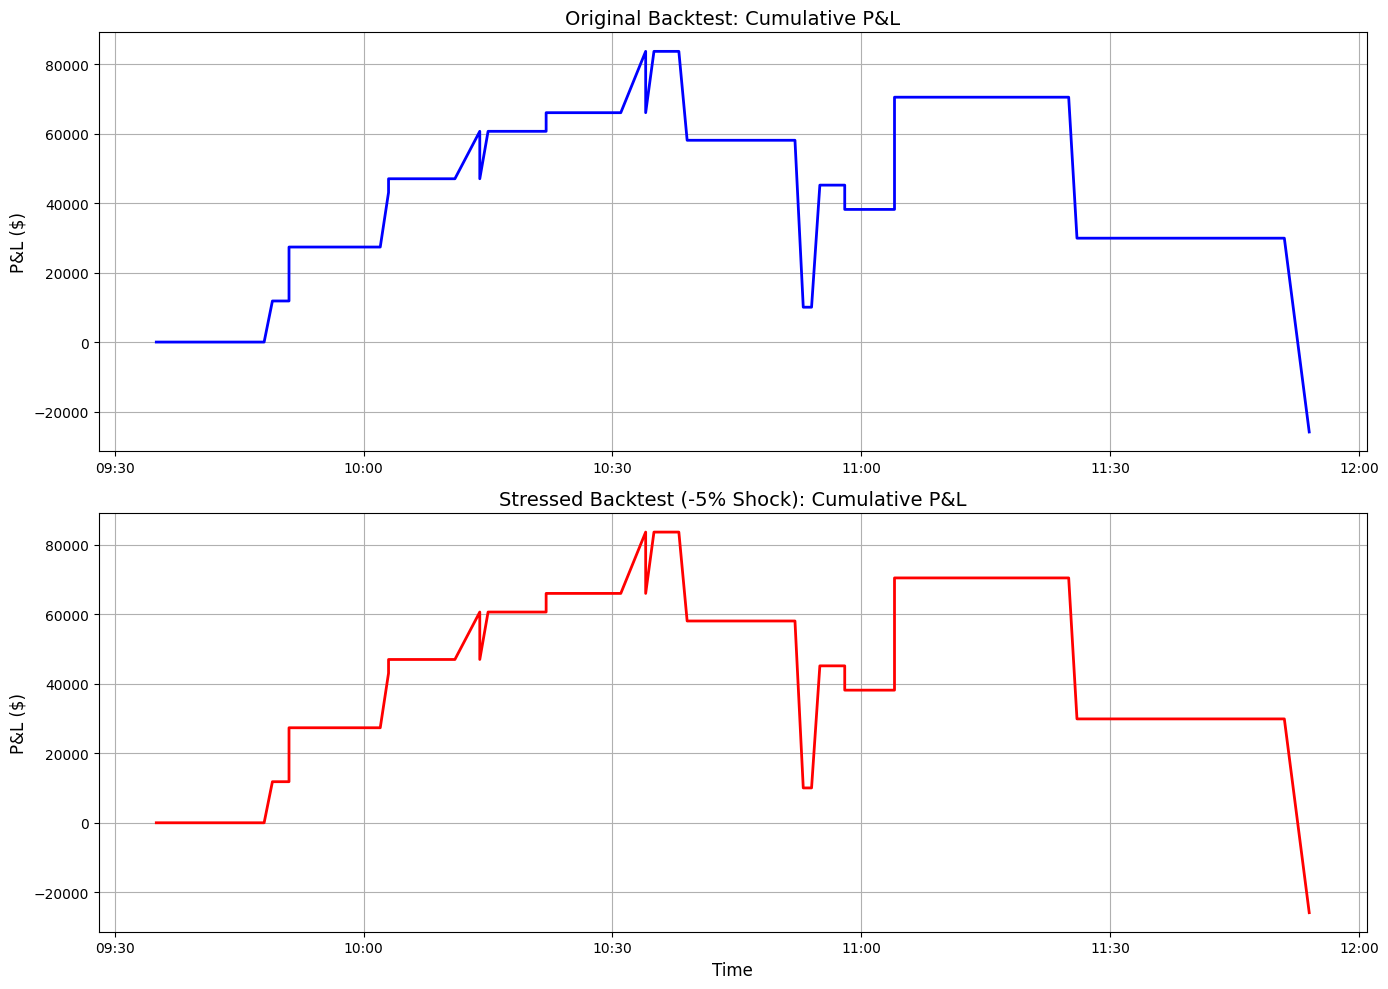

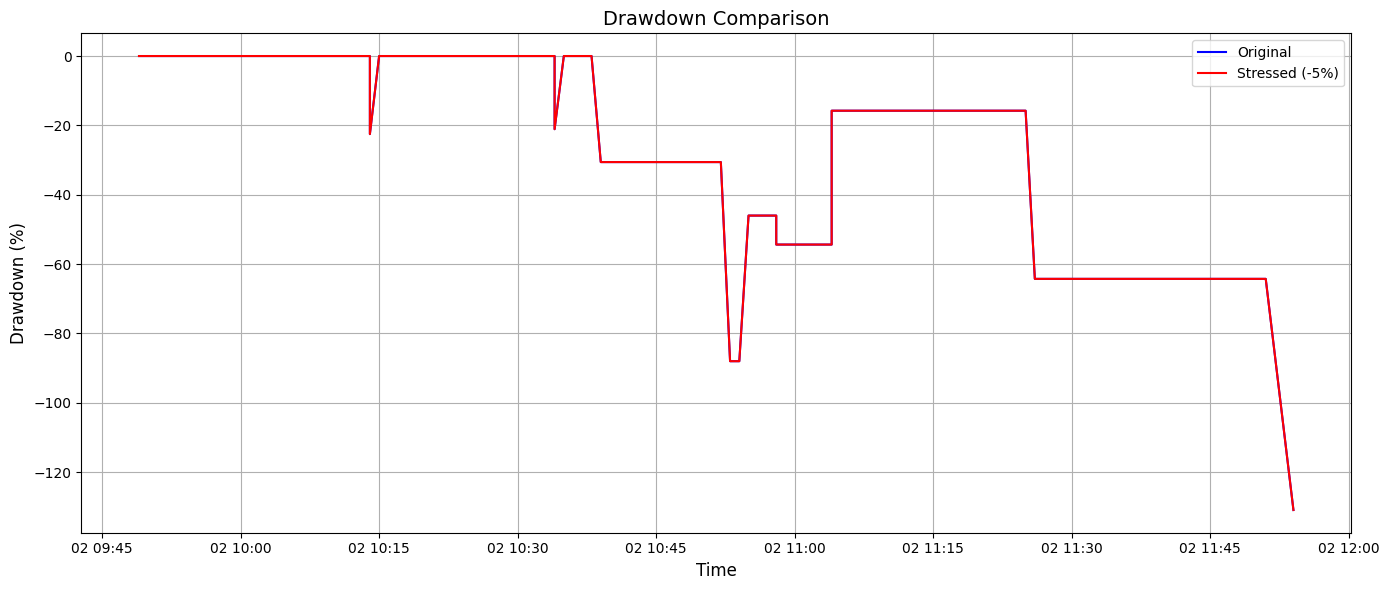

In [28]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.dates import DateFormatter
import pandas as pd

def calculate_performance_metrics(trades_df, name="Backtest"):
    """Calculate key performance metrics from trade data"""
    metrics = {}
    
    # If no trades or no PnL data, return empty metrics
    if len(trades_df) == 0 or 'pnl' not in trades_df.columns:
        print(f"No trade data available for {name}")
        return metrics
    
    # Convert to pandas for easier datetime handling
    df = trades_df.to_pandas()
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    
    # Filter to only completed trades (with PnL)
    completed_trades = df[df['pnl'].notnull()]
    
    # Basic metrics
    metrics['total_trades'] = len(completed_trades)
    metrics['profitable_trades'] = len(completed_trades[completed_trades['pnl'] > 0])
    metrics['win_rate'] = metrics['profitable_trades'] / metrics['total_trades'] if metrics['total_trades'] > 0 else 0
    
    # Return metrics
    metrics['total_pnl'] = completed_trades['pnl'].sum()
    metrics['avg_return'] = completed_trades['pnl'].mean()
    metrics['max_return'] = completed_trades['pnl'].max()
    metrics['min_return'] = completed_trades['pnl'].min()
    
    # 2. Average Win/Loss ratio
    avg_win = completed_trades.loc[completed_trades['pnl'] > 0, 'pnl'].mean() or 0
    avg_loss = abs(completed_trades.loc[completed_trades['pnl'] < 0, 'pnl'].mean() or 1)  # Avoid division by zero
    metrics['avg_win_loss_ratio'] = avg_win / avg_loss if avg_loss != 0 else float('inf')
    
    # Sharpe ratio: assuming 375 minutes in a trading day
    if len(completed_trades) > 1:
        minute_returns = completed_trades.groupby(completed_trades['timestamp'].dt.floor('min'))['pnl'].sum()
        if minute_returns.std() != 0:
            metrics['intraday_sharpe'] = (minute_returns.mean() / minute_returns.std()) * np.sqrt(minute_returns.count())

    # Max drawdown calculation
    if 'cumulative_pnl' in completed_trades.columns:
        cumulative = completed_trades.sort_values('timestamp')
        running_max = cumulative['cumulative_pnl'].cummax()
        drawdown = (cumulative['cumulative_pnl'] - running_max) / running_max if running_max.max() > 0 else 0
        metrics['max_drawdown'] = drawdown.min() if isinstance(drawdown, pd.Series) else 0
    else:
        metrics['max_drawdown'] = 0
    
    return metrics

# Calculate metrics for both datasets
original_metrics = calculate_performance_metrics(trades_df, "Original Backtest")
stressed_metrics = calculate_performance_metrics(stressed_trades_df, "Stressed Backtest (-5% shock)")

# Display metrics in a table
metrics_comparison = pd.DataFrame({
    'Metric': ['Total Trades', 'Win Rate (%)', 'Sharpe Ratio', 'Average Return ($)', 
               'Max Return ($)', 'Min Return ($)', 'Max Drawdown (%)', 'Total P&L ($)'],
    'Original': [original_metrics.get('total_trades', 0),
                f"{original_metrics.get('win_rate', 0)*100:.2f}%",
                f"{original_metrics.get('intraday_sharpe', 0):.2f}",
                f"${original_metrics.get('avg_return', 0):.2f}",
                f"${original_metrics.get('max_return', 0):.2f}",
                f"${original_metrics.get('min_return', 0):.2f}",
                f"{original_metrics.get('max_drawdown', 0)*100:.2f}%",
                f"${original_metrics.get('total_pnl', 0):.2f}"],
    'Stressed (-5%)': [stressed_metrics.get('total_trades', 0),
                      f"{stressed_metrics.get('win_rate', 0)*100:.2f}%",
                      f"{stressed_metrics.get('intraday_sharpe', 0):.2f}",
                      f"${stressed_metrics.get('avg_return', 0):.2f}",
                      f"${stressed_metrics.get('max_return', 0):.2f}",
                      f"${stressed_metrics.get('min_return', 0):.2f}",
                      f"{stressed_metrics.get('max_drawdown', 0)*100:.2f}%",
                      f"${stressed_metrics.get('total_pnl', 0):.2f}"]
})

print(metrics_comparison.to_string(index=False))

# Create P&L curve visualizations
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Plot PnL curves if data exists
if len(trades_df) > 0 and 'cumulative_pnl' in trades_df.columns:
    df1 = trades_df.to_pandas()
    df1['timestamp'] = pd.to_datetime(df1['timestamp'])
    df1 = df1.sort_values('timestamp')
    
    ax1.plot(df1['timestamp'], df1['cumulative_pnl'], 'b-', linewidth=2)
    ax1.set_title('Original Backtest: Cumulative P&L', fontsize=14)
    ax1.set_ylabel('P&L ($)', fontsize=12)
    ax1.grid(True)
    ax1.xaxis.set_major_formatter(DateFormatter('%H:%M'))

# Stressed backtest PnL
if len(trades_df) > 0 and 'cumulative_pnl' in trades_df.columns:
    df2 = trades_df.to_pandas()
    df2['timestamp'] = pd.to_datetime(df2['timestamp'])
    df2 = df2.sort_values('timestamp')
    
    ax2.plot(df2['timestamp'], df2['cumulative_pnl'], 'r-', linewidth=2)
    ax2.set_title('Stressed Backtest (-5% Shock): Cumulative P&L', fontsize=14)
    ax2.set_xlabel('Time', fontsize=12)
    ax2.set_ylabel('P&L ($)', fontsize=12)
    ax2.grid(True)
    ax2.xaxis.set_major_formatter(DateFormatter('%H:%M'))

plt.tight_layout()
plt.show()

# Plot a comparison of drawdowns
if len(trades_df) > 0 and 'cumulative_pnl' in trades_df.columns:
    # Calculate drawdowns for both datasets
    def calculate_drawdowns(df):
        df = df.sort_values('timestamp')
        df['peak'] = df['cumulative_pnl'].cummax()
        df['drawdown'] = (df['cumulative_pnl'] - df['peak']) / df['peak'] * 100
        return df
    
    orig_dd = calculate_drawdowns(trades_df.to_pandas())
    stress_dd = calculate_drawdowns(trades_df.to_pandas())
    
    plt.figure(figsize=(14, 6))
    plt.plot(orig_dd['timestamp'], orig_dd['drawdown'], 'b-', label='Original')
    plt.plot(stress_dd['timestamp'], stress_dd['drawdown'], 'r-', label='Stressed (-5%)')
    plt.title('Drawdown Comparison', fontsize=14)
    plt.xlabel('Time', fontsize=12)
    plt.ylabel('Drawdown (%)', fontsize=12)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()